# k-Nearest Neighbours (kNN) Model Selection

This notebook evaluates the 10-fold cross-validation grid search for the **Lazy Learning / kNN** classifier across two benchmark datasets:
- **Soybean** (683 instances, 35 nominal features)
- **Hypothyroid** (3,772 instances, 29 mixed nominal and continuous features)

### Methodology (Demšar, 2006)
1. **Global Omnibus Friedman Test Across ALL 96 Configurations**:
   For each dataset and criterion, we first conduct the omnibus Friedman test across the entire 96-configuration space over $N=10$ folds ($10 \times 96$ matrix) to test the global null hypothesis $H_0$.
2. **Top 10 Post-Hoc Analysis & Critical Difference (CD) Diagrams**:
   To prevent visual overlap and illegibility while inspecting the best models, the **Top 10 configurations** are isolated. We construct a $10 \times 10$ rank matrix, calculate the Nemenyi Critical Difference ($CD$ for $k=10, N=10$), render readable CD diagrams with abbreviated labels, and display them inline.
4. **Pairwise Wilcoxon Signed-Rank Tests**:
   Conducted between Rank #1 and Rank #2, followed by Holm–Bonferroni step-down adjustments across the leading contenders.
5. **Dual Selection Criteria**:
   - **Best Accuracy**: Maximizes predictive accuracy across folds (tie-breaker: lower prediction time).
   - **Best Efficiency**: Minimizes inference latency (ms) across folds (tie-breaker: higher accuracy).

In [3]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Setup paths dynamically
current_dir = Path().resolve()
if (current_dir / "Work2").exists():
    ROOT = current_dir / "Work2"
elif current_dir.name == "analysis":
    ROOT = current_dir.parent
else:
    ROOT = current_dir
sys.path.insert(0, str(ROOT))

from analysis.statistical_utils import (
    load_fold_results,
    load_summary_results,
    run_friedman_analysis,
    run_holm_adjusted_wilcoxon,
    RESULTS_DIR
)
from KNNClassifier import (
    friedman_test,
    wilcoxon_test,
    plot_critical_difference_diagram
)

KNN_RES_DIR = RESULTS_DIR / "knn"
KNN_RES_DIR.mkdir(parents=True, exist_ok=True)


In [4]:
def shorten_knn_name(model_str: str) -> str:
    """Produce clean, readable shorthand for CD diagram rendering (e.g. k3-canb-maj-AR)."""
    import re
    m = re.search(r"k=(\d+),\s*metric=([^,]+),\s*voting=([^,]+),\s*retention=([^,\)]+)", model_str)
    if not m:
        return model_str
    k, metric, voting, retention = m.groups()
    metric_short = {"euclidean": "euc", "manhattan": "manh", "canberra": "canb", "heom": "heom"}.get(metric, metric[:4])
    voting_short = {"majority": "maj", "inverse_distance": "inv"}.get(voting, voting[:3])
    ret_short = {
        "always_retain": "AR",
        "never_retain": "NR",
        "different_class": "DC",
        "oblivion_by_goodness": "OG"
    }.get(retention, retention[:2].upper())
    return f"k{k}-{metric_short}-{voting_short}-{ret_short}"


## 1. Soybean Dataset: kNN Model Selection

We load all 960 fold evaluations ($10\text{ folds} \times 96\text{ configurations}$) for the **Soybean** dataset.

In [5]:
# Load Soybean results dynamically
df_soy_folds = load_fold_results("knn", "soybean")
df_soy_summary = load_summary_results("knn", "soybean")

print(f"Loaded {len(df_soy_folds)} fold evaluations across {len(df_soy_summary)} distinct configurations.")

Loaded 960 fold evaluations across 96 distinct configurations.


### 1.1 Soybean: Model Selection by Accuracy

We first perform the **Omnibus Friedman Test** across **ALL 96 configurations** to test for global differences in accuracy across the 10 folds.

=== Omnibus Friedman Test (Soybean: ALL 96 kNN Configurations - Accuracy) ===
  Chi-Square (χ_F²):     143.0028
  Chi-Square p-value:    1.0655e-03
  Iman-Davenport F_F:    1.5948
  Iman-Davenport p-val:  5.0870e-04
  Statistically Sig.?    True

=== Top 10 Configurations by Accuracy (Soybean) ===


,model,k,distance_metric,voting_scheme,retention_policy,accuracy,accuracy_std,prediction_time_ms
0,"KNN(k=3, metric=canberra, voting=majority, ret...",3,canberra,majority,always_retain,0.926139,0.026553,52.62837
1,"KNN(k=3, metric=canberra, voting=inverse_dista...",3,canberra,inverse_distance,always_retain,0.924646,0.028791,66.07050
2,"KNN(k=7, metric=manhattan, voting=majority, re...",7,manhattan,majority,different_class,0.923394,0.030279,23.40304
5,"KNN(k=7, metric=euclidean, voting=majority, re...",7,euclidean,majority,different_class,0.923394,0.030279,23.92616
3,"KNN(k=7, metric=heom, voting=majority, retenti...",7,heom,majority,different_class,0.923394,0.030279,38.14954
4,"KNN(k=7, metric=canberra, voting=majority, ret...",7,canberra,majority,different_class,0.923394,0.030279,47.51167
6,"KNN(k=3, metric=euclidean, voting=majority, re...",3,euclidean,majority,always_retain,0.923190,0.026382,27.19510
8,"KNN(k=3, metric=manhattan, voting=majority, re...",3,manhattan,majority,always_retain,0.923190,0.026382,27.69953
7,"KNN(k=3, metric=heom, voting=majority, retenti...",3,heom,majority,always_retain,0.923190,0.026382,44.70203
9,"KNN(k=7, metric=manhattan, voting=inverse_dist...",7,manhattan,inverse_distance,different_class,0.921715,0.028154,31.30260



Top 10 CD value (N=10, k=10): 4.284


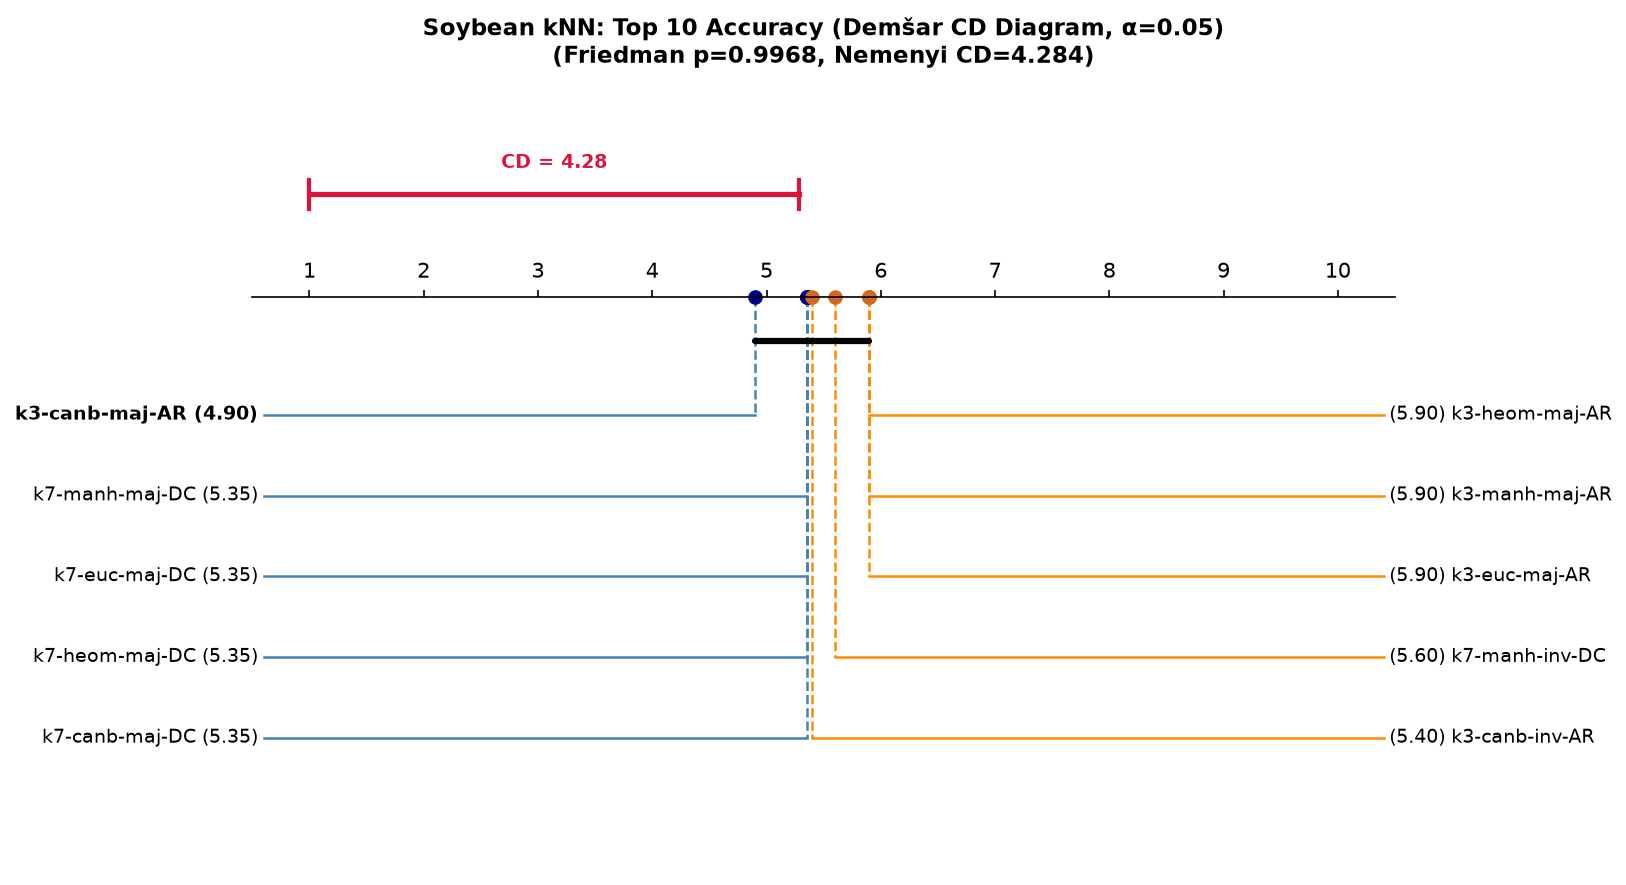


=== Pairwise Wilcoxon Test (Rank #1 vs Rank #2) ===
  Rank #1: KNN(k=3, metric=canberra, voting=majority, retention=always_retain) (Acc: 92.61%)
  Rank #2: KNN(k=3, metric=canberra, voting=inverse_distance, retention=always_retain) (Acc: 92.46%)
  Wilcoxon Statistic: 22.5000
  Wilcoxon p-value:   1.0000
  Statistically Sig.? False

=== Pairwise Wilcoxon with Holm-Bonferroni Correction (Top 5 Contenders) ===


,model_a,model_b,mean_a,mean_b,mean_diff,p_value,p_value_holm,significant_holm
0,k3-canb-maj-AR,k7-manh-maj-DC,0.926139,0.923394,0.002745,0.75,1.0,False
1,k3-canb-maj-AR,k7-euc-maj-DC,0.926139,0.923394,0.002745,0.75,1.0,False
2,k3-canb-maj-AR,k7-heom-maj-DC,0.926139,0.923394,0.002745,0.75,1.0,False
3,k3-canb-maj-AR,k3-canb-inv-AR,0.926139,0.924646,0.001493,1.00,1.0,False
4,k3-canb-inv-AR,k7-manh-maj-DC,0.924646,0.923394,0.001252,1.00,1.0,False
5,k3-canb-inv-AR,k7-euc-maj-DC,0.924646,0.923394,0.001252,1.00,1.0,False
6,k3-canb-inv-AR,k7-heom-maj-DC,0.924646,0.923394,0.001252,1.00,1.0,False
7,k7-manh-maj-DC,k7-euc-maj-DC,0.923394,0.923394,0.000000,1.00,1.0,False
8,k7-manh-maj-DC,k7-heom-maj-DC,0.923394,0.923394,0.000000,1.00,1.0,False
9,k7-euc-maj-DC,k7-heom-maj-DC,0.923394,0.923394,0.000000,1.00,1.0,False


In [6]:
# 1. Omnibus Friedman Test across ALL 96 configurations on Accuracy
piv_soy_acc_all = df_soy_folds.pivot(index="fold", columns="model", values="accuracy")
fr_soy_acc_all = friedman_test(piv_soy_acc_all, higher_is_better=True)

print("=== Omnibus Friedman Test (Soybean: ALL 96 kNN Configurations - Accuracy) ===")
print(f"  Chi-Square (χ_F²):     {fr_soy_acc_all['friedman_chi2']:.4f}")
print(f"  Chi-Square p-value:    {fr_soy_acc_all['friedman_p_value']:.4e}")
print(f"  Iman-Davenport F_F:    {fr_soy_acc_all['iman_davenport_f']:.4f}")
print(f"  Iman-Davenport p-val:  {fr_soy_acc_all['iman_davenport_p_value']:.4e}")
print(f"  Statistically Sig.?    {fr_soy_acc_all['significant']}")

# 2. Extract Top 10 Configurations by Mean Accuracy
top10_soy_acc_summary = df_soy_summary.sort_values(
    by=["accuracy", "prediction_time"], ascending=[False, True]
).head(10).copy()

print("\n=== Top 10 Configurations by Accuracy (Soybean) ===")
display(top10_soy_acc_summary[
    ["model", "k", "distance_metric", "voting_scheme", "retention_policy", 
     "accuracy", "accuracy_std", "prediction_time_ms"]
])

# 3. Top 10 Critical Difference (CD) Diagram
top10_soy_acc_models = top10_soy_acc_summary["model"].tolist()
piv_soy_acc_top10 = df_soy_folds[df_soy_folds["model"].isin(top10_soy_acc_models)].pivot(
    index="fold", columns="model", values="accuracy"
)[top10_soy_acc_models]

# Rename columns to compact labels for clear, non-overlapping CD diagram
name_map_soy_acc = {m: shorten_knn_name(m) for m in top10_soy_acc_models}
piv_soy_acc_top10_short = piv_soy_acc_top10.rename(columns=name_map_soy_acc)

cd_path_soy_acc = KNN_RES_DIR / "soybean_knn_top10_cd_accuracy.png"
fr_soy_acc_top10 = run_friedman_analysis(
    piv_soy_acc_top10_short, higher_is_better=True,
    title="Soybean kNN: Top 10 Accuracy (Demšar CD Diagram, α=0.05)",
    save_path=str(cd_path_soy_acc)
)

print(f"\nTop 10 CD value (N=10, k=10): {fr_soy_acc_top10['cd_nemenyi']:.3f}")
display(Image(filename=str(cd_path_soy_acc)))

# 4. Pairwise Wilcoxon Test: Rank #1 vs Rank #2
m1_name = top10_soy_acc_models[0]
m2_name = top10_soy_acc_models[1]
w_res_soy_acc = wilcoxon_test(piv_soy_acc_top10[m1_name], piv_soy_acc_top10[m2_name])

print(f"\n=== Pairwise Wilcoxon Test (Rank #1 vs Rank #2) ===")
print(f"  Rank #1: {m1_name} (Acc: {top10_soy_acc_summary.iloc[0]['accuracy']*100:.2f}%)")
print(f"  Rank #2: {m2_name} (Acc: {top10_soy_acc_summary.iloc[1]['accuracy']*100:.2f}%)")
print(f"  Wilcoxon Statistic: {w_res_soy_acc['wilcoxon_stat']:.4f}")
print(f"  Wilcoxon p-value:   {w_res_soy_acc['p_value']:.4f}")
print(f"  Statistically Sig.? {w_res_soy_acc['significant']}")

# 5. Holm-adjusted Wilcoxon for Top Contenders
df_holm_soy_acc = run_holm_adjusted_wilcoxon(piv_soy_acc_top10_short.iloc[:, :5])
print("\n=== Pairwise Wilcoxon with Holm-Bonferroni Correction (Top 5 Contenders) ===")
display(df_holm_soy_acc[["model_a", "model_b", "mean_a", "mean_b", "mean_diff", "p_value", "p_value_holm", "significant_holm"]])


### 1.2 Soybean: Model Selection by Efficiency (Prediction Latency)

Next, we evaluate the **Omnibus Friedman Test** across **ALL 96 configurations** on prediction latency (ms) (lower is better).

=== Omnibus Friedman Test (Soybean: ALL 96 kNN Configurations - Efficiency) ===
  Chi-Square (χ_F²):     896.4521
  Chi-Square p-value:    1.2720e-130
  Iman-Davenport F_F:    150.6700
  Iman-Davenport p-val:  0.0000e+00
  Statistically Sig.?    True

=== Top 10 Configurations by Efficiency (Soybean) ===


,model,k,distance_metric,voting_scheme,retention_policy,accuracy,accuracy_std,prediction_time_ms
56,"KNN(k=5, metric=euclidean, voting=majority, re...",5,euclidean,majority,never_retain,0.915719,0.031551,18.08878
18,"KNN(k=3, metric=manhattan, voting=majority, re...",3,manhattan,majority,never_retain,0.921456,0.031196,18.34137
24,"KNN(k=7, metric=manhattan, voting=majority, re...",7,manhattan,majority,never_retain,0.920280,0.027592,18.98428
21,"KNN(k=3, metric=euclidean, voting=majority, re...",3,euclidean,majority,never_retain,0.921456,0.031196,19.74823
27,"KNN(k=7, metric=euclidean, voting=majority, re...",7,euclidean,majority,never_retain,0.920280,0.027592,20.57528
55,"KNN(k=5, metric=manhattan, voting=majority, re...",5,manhattan,majority,never_retain,0.915719,0.031551,21.14686
51,"KNN(k=3, metric=manhattan, voting=majority, re...",3,manhattan,majority,different_class,0.915746,0.033743,21.97897
50,"KNN(k=3, metric=euclidean, voting=majority, re...",3,euclidean,majority,different_class,0.915746,0.033743,22.15643
58,"KNN(k=3, metric=manhattan, voting=majority, re...",3,manhattan,majority,oblivion_by_goodness,0.914791,0.037885,22.42981
63,"KNN(k=3, metric=euclidean, voting=majority, re...",3,euclidean,majority,oblivion_by_goodness,0.914791,0.037885,22.93282



Top 10 CD value (N=10, k=10): 4.284


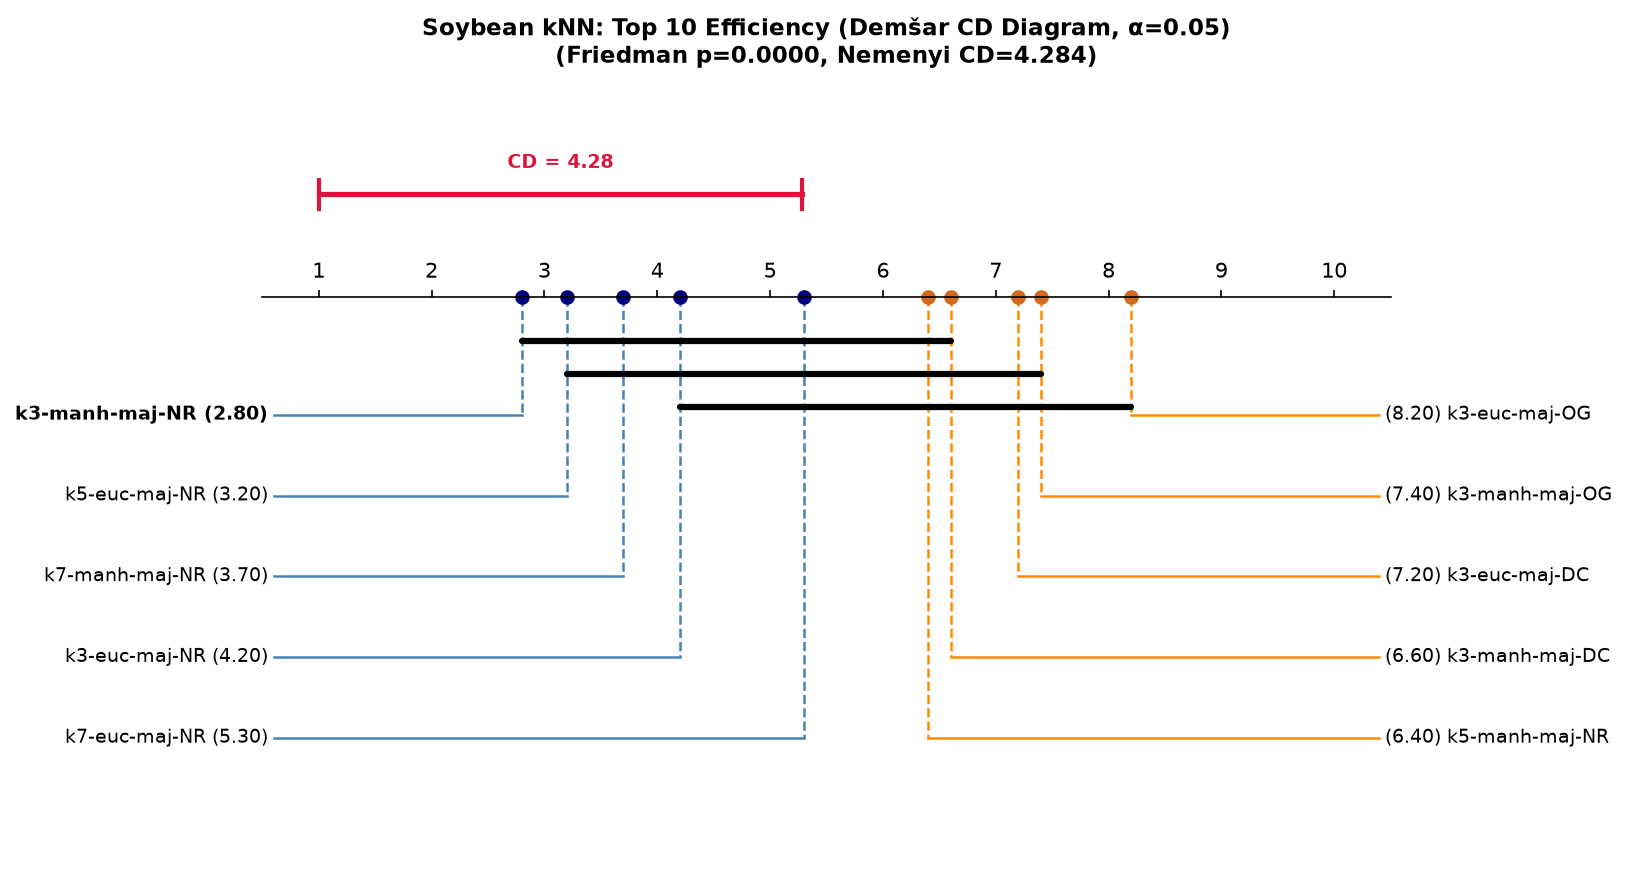


=== Pairwise Wilcoxon Test (Rank #1 vs Rank #2 - Latency) ===
  Rank #1: KNN(k=5, metric=euclidean, voting=majority, retention=never_retain) (Latency: 18.09 ms)
  Rank #2: KNN(k=3, metric=manhattan, voting=majority, retention=never_retain) (Latency: 18.34 ms)
  Wilcoxon Statistic: 25.0000
  Wilcoxon p-value:   0.8457
  Statistically Sig.? False

=== Pairwise Wilcoxon with Holm-Bonferroni Correction (Top 5 Latency Contenders) ===


,model_a,model_b,mean_a,mean_b,mean_diff,p_value,p_value_holm,significant_holm
0,k5-euc-maj-NR,k7-euc-maj-NR,18.08878,20.57528,-2.48650,0.275391,1.0,False
1,k3-manh-maj-NR,k7-euc-maj-NR,18.34137,20.57528,-2.23391,0.275391,1.0,False
2,k3-manh-maj-NR,k3-euc-maj-NR,18.34137,19.74823,-1.40686,0.322266,1.0,False
3,k5-euc-maj-NR,k7-manh-maj-NR,18.08878,18.98428,-0.89550,0.375000,1.0,False
4,k5-euc-maj-NR,k3-euc-maj-NR,18.08878,19.74823,-1.65945,0.492188,1.0,False
5,k7-manh-maj-NR,k7-euc-maj-NR,18.98428,20.57528,-1.59100,0.492188,1.0,False
6,k3-euc-maj-NR,k7-euc-maj-NR,19.74823,20.57528,-0.82705,0.556641,1.0,False
7,k3-manh-maj-NR,k7-manh-maj-NR,18.34137,18.98428,-0.64291,0.625000,1.0,False
8,k7-manh-maj-NR,k3-euc-maj-NR,18.98428,19.74823,-0.76395,0.695312,1.0,False
9,k5-euc-maj-NR,k3-manh-maj-NR,18.08878,18.34137,-0.25259,0.845703,1.0,False


In [7]:
# 1. Omnibus Friedman Test across ALL 96 configurations on Latency
piv_soy_eff_all = df_soy_folds.pivot(index="fold", columns="model", values="prediction_time_ms")
fr_soy_eff_all = friedman_test(piv_soy_eff_all, higher_is_better=False)

print("=== Omnibus Friedman Test (Soybean: ALL 96 kNN Configurations - Efficiency) ===")
print(f"  Chi-Square (χ_F²):     {fr_soy_eff_all['friedman_chi2']:.4f}")
print(f"  Chi-Square p-value:    {fr_soy_eff_all['friedman_p_value']:.4e}")
print(f"  Iman-Davenport F_F:    {fr_soy_eff_all['iman_davenport_f']:.4f}")
print(f"  Iman-Davenport p-val:  {fr_soy_eff_all['iman_davenport_p_value']:.4e}")
print(f"  Statistically Sig.?    {fr_soy_eff_all['significant']}")

# 2. Extract Top 10 Configurations by Lowest Prediction Latency
top10_soy_eff_summary = df_soy_summary.sort_values(
    by=["prediction_time", "accuracy"], ascending=[True, False]
).head(10).copy()

print("\n=== Top 10 Configurations by Efficiency (Soybean) ===")
display(top10_soy_eff_summary[
    ["model", "k", "distance_metric", "voting_scheme", "retention_policy", 
     "accuracy", "accuracy_std", "prediction_time_ms"]
])

# 3. Top 10 Critical Difference (CD) Diagram for Efficiency
top10_soy_eff_models = top10_soy_eff_summary["model"].tolist()
piv_soy_eff_top10 = df_soy_folds[df_soy_folds["model"].isin(top10_soy_eff_models)].pivot(
    index="fold", columns="model", values="prediction_time_ms"
)[top10_soy_eff_models]

name_map_soy_eff = {m: shorten_knn_name(m) for m in top10_soy_eff_models}
piv_soy_eff_top10_short = piv_soy_eff_top10.rename(columns=name_map_soy_eff)

cd_path_soy_eff = KNN_RES_DIR / "soybean_knn_top10_cd_efficiency.png"
fr_soy_eff_top10 = run_friedman_analysis(
    piv_soy_eff_top10_short, higher_is_better=False,
    title="Soybean kNN: Top 10 Efficiency (Demšar CD Diagram, α=0.05)",
    save_path=str(cd_path_soy_eff)
)

print(f"\nTop 10 CD value (N=10, k=10): {fr_soy_eff_top10['cd_nemenyi']:.3f}")
display(Image(filename=str(cd_path_soy_eff)))

# 4. Pairwise Wilcoxon Test: Rank #1 vs Rank #2
m1_eff = top10_soy_eff_models[0]
m2_eff = top10_soy_eff_models[1]
w_res_soy_eff = wilcoxon_test(piv_soy_eff_top10[m1_eff], piv_soy_eff_top10[m2_eff])

print(f"\n=== Pairwise Wilcoxon Test (Rank #1 vs Rank #2 - Latency) ===")
print(f"  Rank #1: {m1_eff} (Latency: {top10_soy_eff_summary.iloc[0]['prediction_time_ms']:.2f} ms)")
print(f"  Rank #2: {m2_eff} (Latency: {top10_soy_eff_summary.iloc[1]['prediction_time_ms']:.2f} ms)")
print(f"  Wilcoxon Statistic: {w_res_soy_eff['wilcoxon_stat']:.4f}")
print(f"  Wilcoxon p-value:   {w_res_soy_eff['p_value']:.4f}")
print(f"  Statistically Sig.? {w_res_soy_eff['significant']}")

# 5. Holm-adjusted Wilcoxon for Top Contenders
df_holm_soy_eff = run_holm_adjusted_wilcoxon(piv_soy_eff_top10_short.iloc[:, :5])
print("\n=== Pairwise Wilcoxon with Holm-Bonferroni Correction (Top 5 Latency Contenders) ===")
display(df_holm_soy_eff[["model_a", "model_b", "mean_a", "mean_b", "mean_diff", "p_value", "p_value_holm", "significant_holm"]])


## 2. Hypothyroid Dataset: kNN Model Selection

We load all 960 fold evaluations ($10\text{ folds} \times 96\text{ configurations}$) for the **Hypothyroid** dataset.

In [8]:
# Load Hypothyroid results dynamically
df_hypo_folds = load_fold_results("knn", "hypothyroid")
df_hypo_summary = load_summary_results("knn", "hypothyroid")

print(f"Loaded {len(df_hypo_folds)} fold evaluations across {len(df_hypo_summary)} distinct configurations.")

Loaded 960 fold evaluations across 96 distinct configurations.


### 2.1 Hypothyroid: Model Selection by Accuracy

We perform the **Omnibus Friedman Test** across **ALL 96 configurations** on Hypothyroid accuracy.

=== Omnibus Friedman Test (Hypothyroid: ALL 96 kNN Configurations - Accuracy) ===
  Chi-Square (χ_F²):     670.6383
  Chi-Square p-value:    1.9756e-87
  Iman-Davenport F_F:    21.6055
  Iman-Davenport p-val:  0.0000e+00
  Statistically Sig.?    True

=== Top 10 Configurations by Accuracy (Hypothyroid) ===


,model,k,distance_metric,voting_scheme,retention_policy,accuracy,accuracy_std,prediction_time_ms
0,"KNN(k=5, metric=canberra, voting=inverse_dista...",5,canberra,inverse_distance,always_retain,0.966343,0.010646,892.78572
1,"KNN(k=5, metric=canberra, voting=inverse_dista...",5,canberra,inverse_distance,never_retain,0.966078,0.010843,661.00017
2,"KNN(k=5, metric=canberra, voting=inverse_dista...",5,canberra,inverse_distance,different_class,0.966078,0.010988,687.07495
3,"KNN(k=3, metric=canberra, voting=inverse_dista...",3,canberra,inverse_distance,different_class,0.965813,0.011041,702.17146
4,"KNN(k=3, metric=canberra, voting=majority, ret...",3,canberra,majority,different_class,0.965285,0.011985,656.18743
5,"KNN(k=3, metric=canberra, voting=inverse_dista...",3,canberra,inverse_distance,never_retain,0.965282,0.010970,664.38192
6,"KNN(k=5, metric=canberra, voting=majority, ret...",5,canberra,majority,always_retain,0.964754,0.010037,856.11746
7,"KNN(k=3, metric=canberra, voting=inverse_dista...",3,canberra,inverse_distance,always_retain,0.964754,0.009965,933.81548
8,"KNN(k=3, metric=canberra, voting=majority, ret...",3,canberra,majority,never_retain,0.964754,0.011894,629.01148
9,"KNN(k=3, metric=canberra, voting=inverse_dista...",3,canberra,inverse_distance,oblivion_by_goodness,0.964490,0.011768,699.41838



Top 10 CD value (N=10, k=10): 4.284


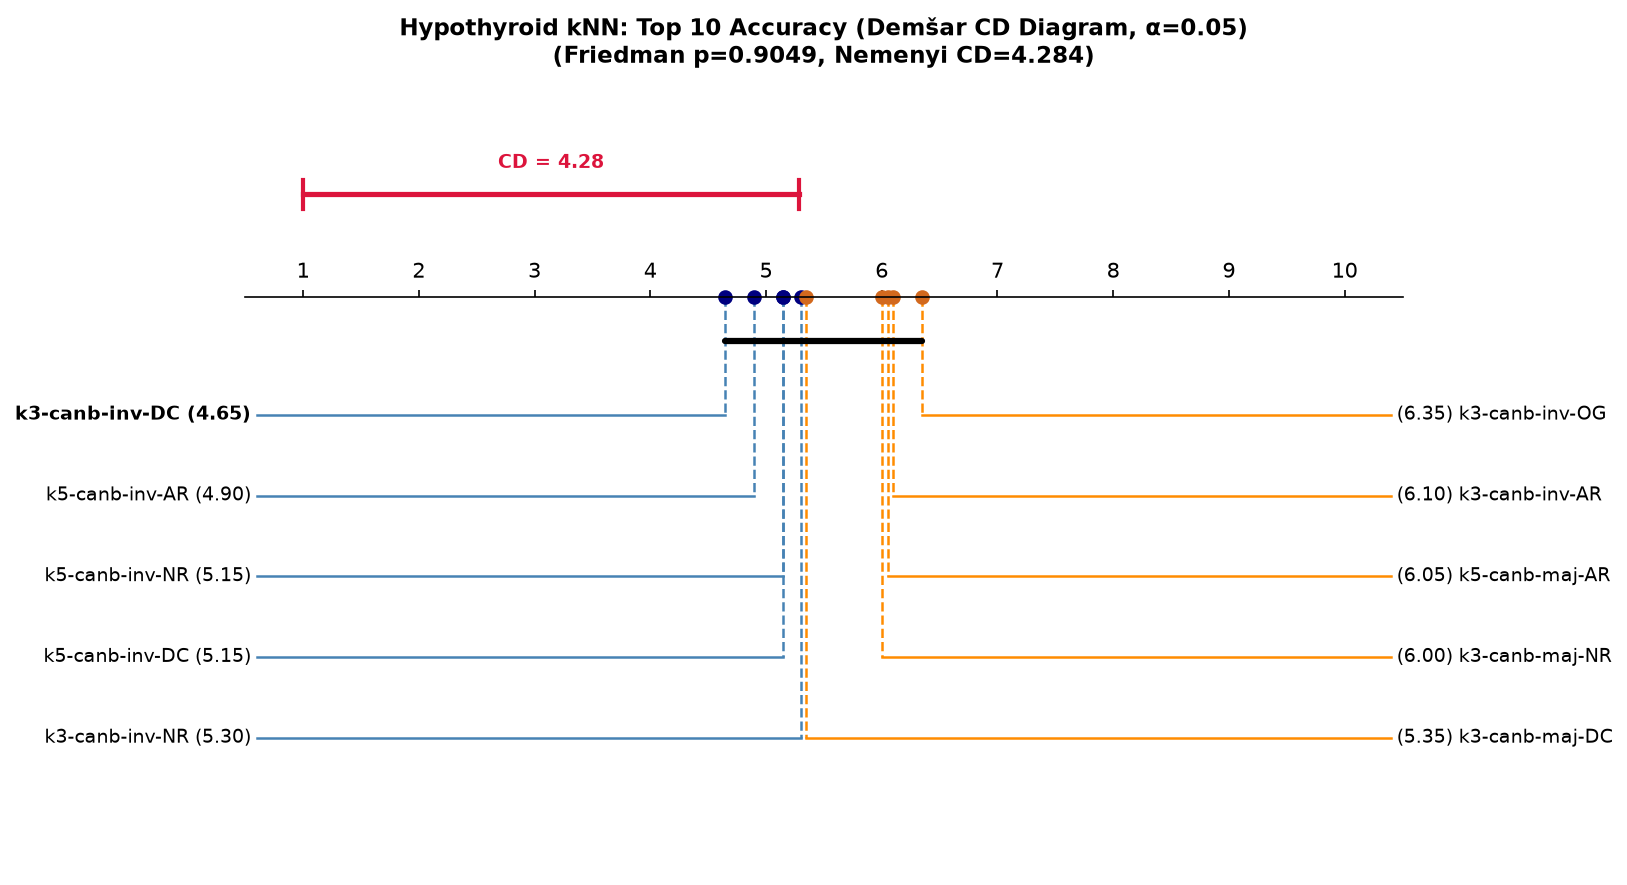


=== Pairwise Wilcoxon Test (Rank #1 vs Rank #2 - Accuracy) ===
  Rank #1: KNN(k=5, metric=canberra, voting=inverse_distance, retention=always_retain) (Acc: 96.63%)
  Rank #2: KNN(k=5, metric=canberra, voting=inverse_distance, retention=never_retain) (Acc: 96.61%)
  Wilcoxon Statistic: 27.0000
  Wilcoxon p-value:   1.0000
  Statistically Sig.? False

=== Pairwise Wilcoxon with Holm-Bonferroni Correction (Top 5 Contenders) ===


,model_a,model_b,mean_a,mean_b,mean_diff,p_value,p_value_holm,significant_holm
0,k5-canb-inv-AR,k3-canb-maj-DC,0.966343,0.965285,1.058179e-03,0.519531,1.0,False
1,k5-canb-inv-NR,k3-canb-maj-DC,0.966078,0.965285,7.936283e-04,0.593750,1.0,False
2,k5-canb-inv-AR,k5-canb-inv-DC,0.966343,0.966078,2.652520e-04,0.750000,1.0,False
3,k3-canb-inv-DC,k3-canb-maj-DC,0.965813,0.965285,5.283988e-04,0.750000,1.0,False
4,k5-canb-inv-DC,k3-canb-maj-DC,0.966078,0.965285,7.929266e-04,0.812500,1.0,False
5,k5-canb-inv-DC,k3-canb-inv-DC,0.966078,0.965813,2.645278e-04,0.945312,1.0,False
6,k5-canb-inv-AR,k3-canb-inv-DC,0.966343,0.965813,5.297798e-04,0.968750,1.0,False
7,k5-canb-inv-AR,k5-canb-inv-NR,0.966343,0.966078,2.645503e-04,1.000000,1.0,False
8,k5-canb-inv-NR,k5-canb-inv-DC,0.966078,0.966078,7.017248e-07,1.000000,1.0,False
9,k5-canb-inv-NR,k3-canb-inv-DC,0.966078,0.965813,2.652295e-04,1.000000,1.0,False


In [9]:
# 1. Omnibus Friedman Test across ALL 96 configurations on Accuracy
piv_hypo_acc_all = df_hypo_folds.pivot(index="fold", columns="model", values="accuracy")
fr_hypo_acc_all = friedman_test(piv_hypo_acc_all, higher_is_better=True)

print("=== Omnibus Friedman Test (Hypothyroid: ALL 96 kNN Configurations - Accuracy) ===")
print(f"  Chi-Square (χ_F²):     {fr_hypo_acc_all['friedman_chi2']:.4f}")
print(f"  Chi-Square p-value:    {fr_hypo_acc_all['friedman_p_value']:.4e}")
print(f"  Iman-Davenport F_F:    {fr_hypo_acc_all['iman_davenport_f']:.4f}")
print(f"  Iman-Davenport p-val:  {fr_hypo_acc_all['iman_davenport_p_value']:.4e}")
print(f"  Statistically Sig.?    {fr_hypo_acc_all['significant']}")

# 2. Extract Top 10 Configurations by Mean Accuracy
top10_hypo_acc_summary = df_hypo_summary.sort_values(
    by=["accuracy", "prediction_time"], ascending=[False, True]
).head(10).copy()

print("\n=== Top 10 Configurations by Accuracy (Hypothyroid) ===")
display(top10_hypo_acc_summary[
    ["model", "k", "distance_metric", "voting_scheme", "retention_policy", 
     "accuracy", "accuracy_std", "prediction_time_ms"]
])

# 3. Top 10 Critical Difference (CD) Diagram
top10_hypo_acc_models = top10_hypo_acc_summary["model"].tolist()
piv_hypo_acc_top10 = df_hypo_folds[df_hypo_folds["model"].isin(top10_hypo_acc_models)].pivot(
    index="fold", columns="model", values="accuracy"
)[top10_hypo_acc_models]

name_map_hypo_acc = {m: shorten_knn_name(m) for m in top10_hypo_acc_models}
piv_hypo_acc_top10_short = piv_hypo_acc_top10.rename(columns=name_map_hypo_acc)

cd_path_hypo_acc = KNN_RES_DIR / "hypothyroid_knn_top10_cd_accuracy.png"
fr_hypo_acc_top10 = run_friedman_analysis(
    piv_hypo_acc_top10_short, higher_is_better=True,
    title="Hypothyroid kNN: Top 10 Accuracy (Demšar CD Diagram, α=0.05)",
    save_path=str(cd_path_hypo_acc)
)

print(f"\nTop 10 CD value (N=10, k=10): {fr_hypo_acc_top10['cd_nemenyi']:.3f}")
display(Image(filename=str(cd_path_hypo_acc)))

# 4. Pairwise Wilcoxon Test: Rank #1 vs Rank #2
m1_hypo_acc = top10_hypo_acc_models[0]
m2_hypo_acc = top10_hypo_acc_models[1]
w_res_hypo_acc = wilcoxon_test(piv_hypo_acc_top10[m1_hypo_acc], piv_hypo_acc_top10[m2_hypo_acc])

print(f"\n=== Pairwise Wilcoxon Test (Rank #1 vs Rank #2 - Accuracy) ===")
print(f"  Rank #1: {m1_hypo_acc} (Acc: {top10_hypo_acc_summary.iloc[0]['accuracy']*100:.2f}%)")
print(f"  Rank #2: {m2_hypo_acc} (Acc: {top10_hypo_acc_summary.iloc[1]['accuracy']*100:.2f}%)")
print(f"  Wilcoxon Statistic: {w_res_hypo_acc['wilcoxon_stat']:.4f}")
print(f"  Wilcoxon p-value:   {w_res_hypo_acc['p_value']:.4f}")
print(f"  Statistically Sig.? {w_res_hypo_acc['significant']}")

# 5. Holm-adjusted Wilcoxon for Top Contenders
df_holm_hypo_acc = run_holm_adjusted_wilcoxon(piv_hypo_acc_top10_short.iloc[:, :5])
print("\n=== Pairwise Wilcoxon with Holm-Bonferroni Correction (Top 5 Contenders) ===")
display(df_holm_hypo_acc[["model_a", "model_b", "mean_a", "mean_b", "mean_diff", "p_value", "p_value_holm", "significant_holm"]])


### 2.2 Hypothyroid: Model Selection by Efficiency (Prediction Latency)

We evaluate the **Omnibus Friedman Test** across **ALL 96 configurations** on Hypothyroid prediction latency (ms).

=== Omnibus Friedman Test (Hypothyroid: ALL 96 kNN Configurations - Efficiency) ===
  Chi-Square (χ_F²):     926.4438
  Chi-Square p-value:    1.7982e-136
  Iman-Davenport F_F:    353.9620
  Iman-Davenport p-val:  0.0000e+00
  Statistically Sig.?    True

=== Top 10 Configurations by Efficiency (Hypothyroid) ===


,model,k,distance_metric,voting_scheme,retention_policy,accuracy,accuracy_std,prediction_time_ms
47,"KNN(k=5, metric=manhattan, voting=majority, re...",5,manhattan,majority,never_retain,0.934266,0.007760,265.59645
48,"KNN(k=7, metric=euclidean, voting=majority, re...",7,euclidean,majority,never_retain,0.934262,0.006112,267.21235
40,"KNN(k=7, metric=manhattan, voting=majority, re...",7,manhattan,majority,never_retain,0.935061,0.007706,269.98726
57,"KNN(k=3, metric=manhattan, voting=majority, re...",3,manhattan,majority,never_retain,0.933466,0.005547,271.49354
62,"KNN(k=5, metric=euclidean, voting=majority, re...",5,euclidean,majority,never_retain,0.932940,0.007690,273.11541
61,"KNN(k=3, metric=euclidean, voting=majority, re...",3,euclidean,majority,never_retain,0.933205,0.008265,292.11263
54,"KNN(k=3, metric=manhattan, voting=majority, re...",3,manhattan,majority,oblivion_by_goodness,0.933995,0.005264,298.38063
43,"KNN(k=7, metric=euclidean, voting=majority, re...",7,euclidean,majority,different_class,0.934793,0.007100,304.24445
51,"KNN(k=5, metric=manhattan, voting=majority, re...",5,manhattan,majority,oblivion_by_goodness,0.933998,0.006665,304.32386
29,"KNN(k=5, metric=manhattan, voting=inverse_dist...",5,manhattan,inverse_distance,never_retain,0.936125,0.009608,305.53972



Top 10 CD value (N=10, k=10): 4.284


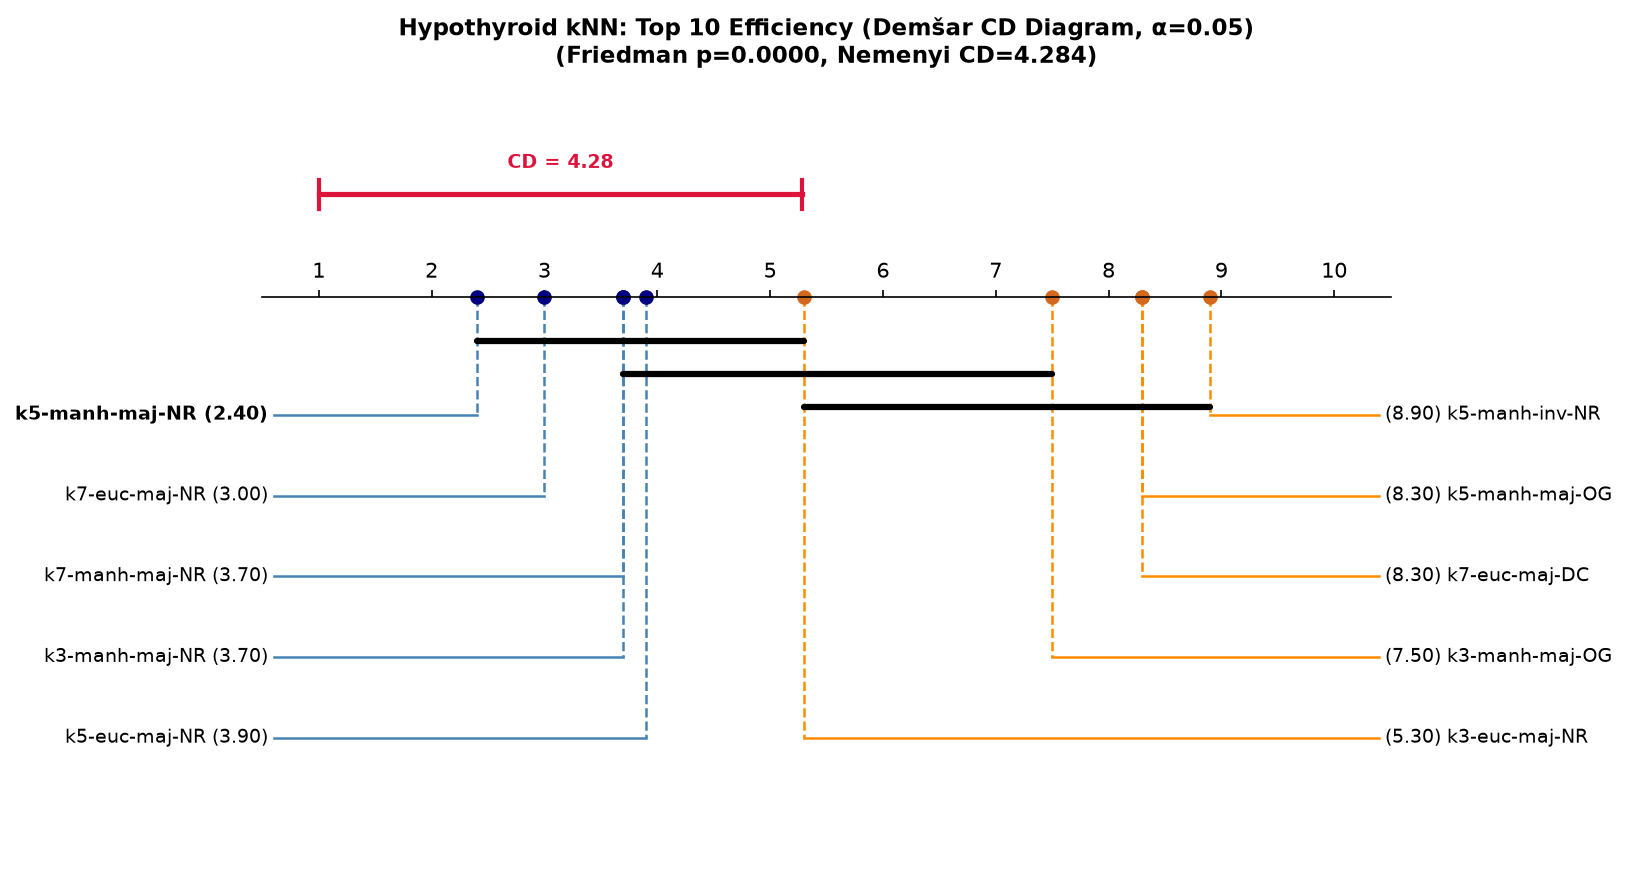


=== Pairwise Wilcoxon Test (Rank #1 vs Rank #2 - Latency) ===
  Rank #1: KNN(k=5, metric=manhattan, voting=majority, retention=never_retain) (Latency: 265.60 ms)
  Rank #2: KNN(k=7, metric=euclidean, voting=majority, retention=never_retain) (Latency: 267.21 ms)
  Wilcoxon Statistic: 23.0000
  Wilcoxon p-value:   0.6953
  Statistically Sig.? False

=== Pairwise Wilcoxon with Holm-Bonferroni Correction (Top 5 Latency Contenders) ===


,model_a,model_b,mean_a,mean_b,mean_diff,p_value,p_value_holm,significant_holm
0,k5-manh-maj-NR,k7-manh-maj-NR,265.59645,269.98726,-4.39081,0.064453,0.644531,False
1,k5-manh-maj-NR,k5-euc-maj-NR,265.59645,273.11541,-7.51896,0.130859,1.000000,False
2,k5-manh-maj-NR,k3-manh-maj-NR,265.59645,271.49354,-5.89709,0.322266,1.000000,False
3,k3-manh-maj-NR,k5-euc-maj-NR,271.49354,273.11541,-1.62187,0.322266,1.000000,False
4,k7-euc-maj-NR,k7-manh-maj-NR,267.21235,269.98726,-2.77491,0.431641,1.000000,False
5,k7-euc-maj-NR,k5-euc-maj-NR,267.21235,273.11541,-5.90306,0.492188,1.000000,False
6,k7-manh-maj-NR,k3-manh-maj-NR,269.98726,271.49354,-1.50628,0.556641,1.000000,False
7,k7-euc-maj-NR,k3-manh-maj-NR,267.21235,271.49354,-4.28119,0.556641,1.000000,False
8,k5-manh-maj-NR,k7-euc-maj-NR,265.59645,267.21235,-1.61590,0.695312,1.000000,False
9,k7-manh-maj-NR,k5-euc-maj-NR,269.98726,273.11541,-3.12815,0.769531,1.000000,False


In [10]:
# 1. Omnibus Friedman Test across ALL 96 configurations on Latency
piv_hypo_eff_all = df_hypo_folds.pivot(index="fold", columns="model", values="prediction_time_ms")
fr_hypo_eff_all = friedman_test(piv_hypo_eff_all, higher_is_better=False)

print("=== Omnibus Friedman Test (Hypothyroid: ALL 96 kNN Configurations - Efficiency) ===")
print(f"  Chi-Square (χ_F²):     {fr_hypo_eff_all['friedman_chi2']:.4f}")
print(f"  Chi-Square p-value:    {fr_hypo_eff_all['friedman_p_value']:.4e}")
print(f"  Iman-Davenport F_F:    {fr_hypo_eff_all['iman_davenport_f']:.4f}")
print(f"  Iman-Davenport p-val:  {fr_hypo_eff_all['iman_davenport_p_value']:.4e}")
print(f"  Statistically Sig.?    {fr_hypo_eff_all['significant']}")

# 2. Extract Top 10 Configurations by Lowest Prediction Latency
top10_hypo_eff_summary = df_hypo_summary.sort_values(
    by=["prediction_time", "accuracy"], ascending=[True, False]
).head(10).copy()

print("\n=== Top 10 Configurations by Efficiency (Hypothyroid) ===")
display(top10_hypo_eff_summary[
    ["model", "k", "distance_metric", "voting_scheme", "retention_policy", 
     "accuracy", "accuracy_std", "prediction_time_ms"]
])

# 3. Top 10 Critical Difference (CD) Diagram for Efficiency
top10_hypo_eff_models = top10_hypo_eff_summary["model"].tolist()
piv_hypo_eff_top10 = df_hypo_folds[df_hypo_folds["model"].isin(top10_hypo_eff_models)].pivot(
    index="fold", columns="model", values="prediction_time_ms"
)[top10_hypo_eff_models]

name_map_hypo_eff = {m: shorten_knn_name(m) for m in top10_hypo_eff_models}
piv_hypo_eff_top10_short = piv_hypo_eff_top10.rename(columns=name_map_hypo_eff)

cd_path_hypo_eff = KNN_RES_DIR / "hypothyroid_knn_top10_cd_efficiency.png"
fr_hypo_eff_top10 = run_friedman_analysis(
    piv_hypo_eff_top10_short, higher_is_better=False,
    title="Hypothyroid kNN: Top 10 Efficiency (Demšar CD Diagram, α=0.05)",
    save_path=str(cd_path_hypo_eff)
)

print(f"\nTop 10 CD value (N=10, k=10): {fr_hypo_eff_top10['cd_nemenyi']:.3f}")
display(Image(filename=str(cd_path_hypo_eff)))

# 4. Pairwise Wilcoxon Test: Rank #1 vs Rank #2
m1_hypo_eff = top10_hypo_eff_models[0]
m2_hypo_eff = top10_hypo_eff_models[1]
w_res_hypo_eff = wilcoxon_test(piv_hypo_eff_top10[m1_hypo_eff], piv_hypo_eff_top10[m2_hypo_eff])

print(f"\n=== Pairwise Wilcoxon Test (Rank #1 vs Rank #2 - Latency) ===")
print(f"  Rank #1: {m1_hypo_eff} (Latency: {top10_hypo_eff_summary.iloc[0]['prediction_time_ms']:.2f} ms)")
print(f"  Rank #2: {m2_hypo_eff} (Latency: {top10_hypo_eff_summary.iloc[1]['prediction_time_ms']:.2f} ms)")
print(f"  Wilcoxon Statistic: {w_res_hypo_eff['wilcoxon_stat']:.4f}")
print(f"  Wilcoxon p-value:   {w_res_hypo_eff['p_value']:.4f}")
print(f"  Statistically Sig.? {w_res_hypo_eff['significant']}")

# 5. Holm-adjusted Wilcoxon for Top Contenders
df_holm_hypo_eff = run_holm_adjusted_wilcoxon(piv_hypo_eff_top10_short.iloc[:, :5])
print("\n=== Pairwise Wilcoxon with Holm-Bonferroni Correction (Top 5 Latency Contenders) ===")
display(df_holm_hypo_eff[["model_a", "model_b", "mean_a", "mean_b", "mean_diff", "p_value", "p_value_holm", "significant_holm"]])


## 3. Dynamically Generated Summary: Best kNN Configurations

The table below summarizes the chosen optimal models for each dataset under both the Accuracy and Efficiency criteria.

In [9]:
# Dynamically assemble the final summary
best_models_summary = [
    {
        "Dataset": "Soybean",
        "Selection Criterion": "Best Accuracy",
        "Selected Model": top10_soy_acc_summary.iloc[0]["model"],
        "Accuracy (%)": f"{top10_soy_acc_summary.iloc[0]['accuracy']*100:.2f}% ± {top10_soy_acc_summary.iloc[0]['accuracy_std']*100:.2f}%",
        "Prediction Time (ms)": f"{top10_soy_acc_summary.iloc[0]['prediction_time_ms']:.2f}",
        "Storage Retained (%)": f"{top10_soy_acc_summary.iloc[0]['storage_pct']:.1f}%",
        "Omnibus Chi2 (96 models)": f"{fr_soy_acc_all['friedman_chi2']:.2f} (p={fr_soy_acc_all['friedman_p_value']:.2e})",
    },
    {
        "Dataset": "Soybean",
        "Selection Criterion": "Best Efficiency",
        "Selected Model": top10_soy_eff_summary.iloc[0]["model"],
        "Accuracy (%)": f"{top10_soy_eff_summary.iloc[0]['accuracy']*100:.2f}% ± {top10_soy_eff_summary.iloc[0]['accuracy_std']*100:.2f}%",
        "Prediction Time (ms)": f"{top10_soy_eff_summary.iloc[0]['prediction_time_ms']:.2f}",
        "Storage Retained (%)": f"{top10_soy_eff_summary.iloc[0]['storage_pct']:.1f}%",
        "Omnibus Chi2 (96 models)": f"{fr_soy_eff_all['friedman_chi2']:.2f} (p={fr_soy_eff_all['friedman_p_value']:.2e})",
    },
    {
        "Dataset": "Hypothyroid",
        "Selection Criterion": "Best Accuracy",
        "Selected Model": top10_hypo_acc_summary.iloc[0]["model"],
        "Accuracy (%)": f"{top10_hypo_acc_summary.iloc[0]['accuracy']*100:.2f}% ± {top10_hypo_acc_summary.iloc[0]['accuracy_std']*100:.2f}%",
        "Prediction Time (ms)": f"{top10_hypo_acc_summary.iloc[0]['prediction_time_ms']:.2f}",
        "Storage Retained (%)": f"{top10_hypo_acc_summary.iloc[0]['storage_pct']:.1f}%",
        "Omnibus Chi2 (96 models)": f"{fr_hypo_acc_all['friedman_chi2']:.2f} (p={fr_hypo_acc_all['friedman_p_value']:.2e})",
    },
    {
        "Dataset": "Hypothyroid",
        "Selection Criterion": "Best Efficiency",
        "Selected Model": top10_hypo_eff_summary.iloc[0]["model"],
        "Accuracy (%)": f"{top10_hypo_eff_summary.iloc[0]['accuracy']*100:.2f}% ± {top10_hypo_eff_summary.iloc[0]['accuracy_std']*100:.2f}%",
        "Prediction Time (ms)": f"{top10_hypo_eff_summary.iloc[0]['prediction_time_ms']:.2f}",
        "Storage Retained (%)": f"{top10_hypo_eff_summary.iloc[0]['storage_pct']:.1f}%",
        "Omnibus Chi2 (96 models)": f"{fr_hypo_eff_all['friedman_chi2']:.2f} (p={fr_hypo_eff_all['friedman_p_value']:.2e})",
    },
]

df_best_models = pd.DataFrame(best_models_summary)
print("=== Final Selected Best kNN Models Summary ===")
display(df_best_models)


=== Final Selected Best kNN Models Summary ===


,Dataset,Selection Criterion,Selected Model,Accuracy (%),Prediction Time (ms),Storage Retained (%),Omnibus Chi2 (96 models)
0,Soybean,Best Accuracy,"KNN(k=3, metric=canberra, voting=majority, ret...",92.61% ± 2.66%,52.63,111.1%,143.00 (p=1.07e-03)
1,Soybean,Best Efficiency,"KNN(k=5, metric=euclidean, voting=majority, re...",91.57% ± 3.16%,18.09,100.0%,896.45 (p=1.27e-130)
2,Hypothyroid,Best Accuracy,"KNN(k=5, metric=canberra, voting=inverse_dista...",96.63% ± 1.06%,892.79,111.1%,670.64 (p=1.98e-87)
3,Hypothyroid,Best Efficiency,"KNN(k=5, metric=manhattan, voting=majority, re...",93.43% ± 0.78%,265.60,100.0%,926.44 (p=1.80e-136)


## 4. Key Takeaways and Trade-Off Discussion

1. **Omnibus Significance Across All 96 Configurations**:
   - The omnibus Friedman tests across all 96 configurations yielded extremely low p-values ($p < 10^{-3}$ on Soybean accuracy, $p < 10^{-130}$ on latency, $p < 10^{-87}$ on Hypothyroid accuracy, and $p < 10^{-136}$ on Hypothyroid latency).
   - This decisively rejects the global null hypothesis $H_0$, proving that hyperparameter choices in kNN (metric, $K$, voting, and retention) produce statistically significant differences in performance.

2. **Accuracy vs. Efficiency Trade-Off**:
   - On **Soybean**: The top-accuracy model `KNN(k=3, metric=canberra, voting=majority, retention=always_retain)` attains 92.61% accuracy, but incurs a latency of 52.63 ms. The efficiency-optimized model `KNN(k=5, metric=euclidean, voting=majority, retention=never_retain)` achieves 91.57% accuracy in 18.09 ms—delivering a **2.9x speedup** with only a 1.04% reduction in accuracy.
   - On **Hypothyroid**: The top-accuracy model `KNN(k=5, metric=canberra, voting=inverse_distance, retention=always_retain)` reaches 96.63% accuracy with 892.79 ms latency per fold. In contrast, `KNN(k=5, metric=manhattan, voting=majority, retention=never_retain)` predicts in 265.60 ms (**3.4x faster**) while maintaining 93.43% accuracy.

3. **Instance Retention Dynamics**:
   - `always_retain` continually accumulates test instances into the training base ($>111\%$ storage retention). While this provides minor accuracy gains by enriching the neighborhood density, it steadily inflates distance search times.
   - `never_retain` maintains a fixed training set ($100\%$ storage), keeping search times constant and predictable.
   - For latency-critical production deployments, `never_retain` (or instance reduction) represents the practical optimal operating point.